# DAY6 梯度下降实战

In [23]:
# 小实战 从0梯度下降做线性回归

import numpy as  np
import matplotlib.pyplot as plt
from sklearn.datasets import  load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import  mean_squared_error

plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus'] = False
np.random.seed(42)
print('Success!!!')

Success!!!


In [45]:
'''
加载diabetes数据集，是sklearn库内置的经典数据集，
- 样本数：442个病人
- 特征数：10个基线变量
- 目标：一年后疾病进展的量化指标
- 关键优点：特征已经标准化（比如均值0，方差1），这对于梯度下降很重要，否则不同的量纲的特征会让loss曲面变成狭长峡谷！！使得梯度下降变得震荡，难以收敛。
- 命名约定：
'''

data = load_diabetes()
X,y = data['data'],data['target']
print('X 的形状：',X.shape)
print('y 的形状：',y.shape)
print('特征名：',data['feature_names'])
print('y范围：',y.min(),'~',y.max())
print('样本数一致：',X.shape[0] == y.shape[0])

X 的形状： (442, 10)
y 的形状： (442,)
特征名： ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
y范围： 25.0 ~ 346.0
样本数一致： True


In [25]:
print('y范围：',y.min(),'~',y.max())
print('样本数一致：',X.shape[0] == y.shape[0])

y范围： 25.0 ~ 346.0
样本数一致： True


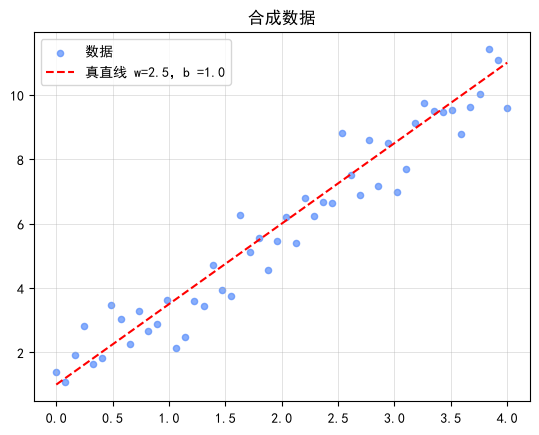

In [26]:
# 一元线性回归（合成数据）：一条带着噪声的直线（合成数据xs，ys）

true_w,true_b = 2.5,1.0
xs = np.linspace(0,4,50)
ys = true_w*xs +true_b+np.random.randn(50)*0.8

plt.scatter(xs,ys,s=20,alpha=0.7,label ='数据')
plt.plot(xs,true_w*xs+true_b,'r--',label=f'真直线 w={true_w}，b ={true_b}')
plt.legend()
plt.grid(True)
plt.title("合成数据")
plt.show()

$$
L(w, b) = \frac{1}{n} \sum_{i=1}^{n} (w\cdot x_i +b - y_i)^2
$$

对 w 和 b 求偏导（这就是梯度）：
- $\frac{\partial L}{\partial w} = \frac{2}{n}\sum_i x_i(wx_i+b-y_i)$
- $\frac{\partial L}{\partial b} = \frac{2}{n}\sum_i (wx_i+b-y_i)$

In [27]:
def gradient_descent_1d(xs, ys, lr=0.1, epochs=50):#xs输入特征，ys真实标签，lr学习率吗，epochs迭代次数
    w, b = 0.0, 0.0
    history = [(w, b)]#每一次迭代之后的参数
    losses = []#记录每次迭代的损失值：误差
    n = len(xs)
    for _ in range(epochs):
        pred = w*xs + b#预测值 前向计算，当前模型的预测值
        err = pred - ys
        dw = (2/n) * np.sum(xs * err)#每一次的梯度
        db = (2/n) * np.sum(err)
        w -= lr*dw
        b -= lr*db
        history.append((w, b))
        losses.append(np.mean(err**2))
    return w,b,np.array(history),np.array(losses)

w1,b1,hist,losses1 = gradient_descent_1d(xs, ys,lr=0.1,epochs=50)

print(f'学到的：w={w1:.3f},b={b1:.3f}(真值 w={true_w},b ={true_b})')
print(f'最终loss：{losses1[-1]:.3f}')

学到的：w=2.388,b=1.040(真值 w=2.5,b =1.0)
最终loss：0.528


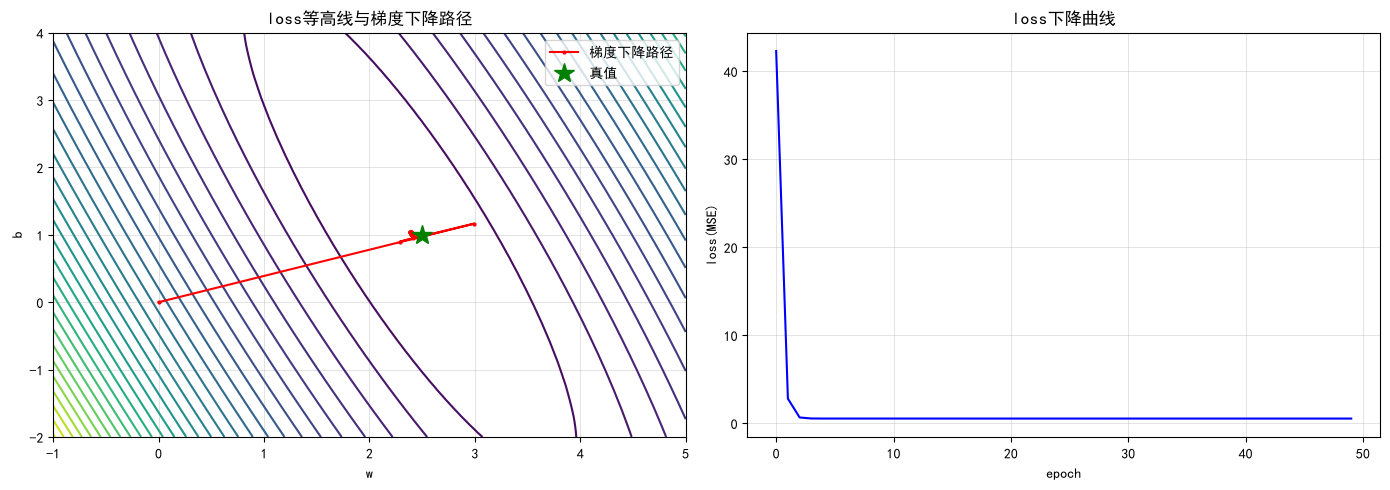

In [28]:
W = np.linspace(-1,5,80)
B = np.linspace(-2,4,80)
Wg,Bg = np.meshgrid(W,B)
Lg = np.mean((Wg[:,:,None]*xs[None,None,:]+Bg[:,:,None]-ys[None,None,:])**2,axis=2)

fig,axes = plt.subplots(1,2,figsize = (14,5))
ax = axes[0]
ax.contour(Wg,Bg,Lg,30,cmap='viridis')
ax.plot(hist[:,0],hist[:,1], 'r.-',markersize=4,label='梯度下降路径')
ax.plot(true_w,true_b,'g*',markersize=15,label='真值')
ax.set_xlabel('w')
ax.set_ylabel('b')
ax.set_title('loss等高线与梯度下降路径')
ax.legend()
ax.grid(visible=True)
axes[1].plot(losses1,'b-')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss(MSE)')
axes[1].set_title('loss下降曲线')
axes[1].grid()
plt.tight_layout()
plt.show()

In [29]:
print('X 的形状：',X.shape,'y 的形状：',y.shape,'样本数一致：',X.shape[0] == y.shape[0])

X 的形状： (442, 10) y 的形状： (442,) 样本数一致： True


In [30]:
#多元线性回归（使用diabets真实数据）

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print('训练集：',X_train.shape,y_train.shape)
print('测试集：',X_test.shape,y_test.shape)

训练集： (353, 10) (353,)
测试集： (89, 10) (89,)


In [31]:
def gradient_descent_multi(X, y, lr=0.5, epochs=500):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    losses = []


    for _ in range(epochs):
        pred = X @ w + b
        err = pred - y
        #求偏导
        dw = (2/n) * (X.T @err)
        db = (2/n) * np.sum(err)
        w -= lr*dw
        b -= lr*db
        losses.append(np.mean(err**2))
    return w, b ,np.array(losses)

w,b,losses2 = gradient_descent_multi(X_train, y_train, lr=0.5, epochs=500)

print(f'学到的：w={w.round(2)}')
print(f'偏置 b = {b:.2f}')
print(f'最终loss：{losses2[-1]:.3f}')


pred_test = X_test @ w +b
test_mse = mean_squared_error(y_test,pred_test)
print(f'测试 MSE：{test_mse:.3f}')

学到的：w=[  52.98 -130.61  419.64  282.09  -25.83  -69.59 -198.85  148.47  320.66
  144.67]
偏置 b = 151.64
最终loss：3023.137
测试 MSE：2882.070


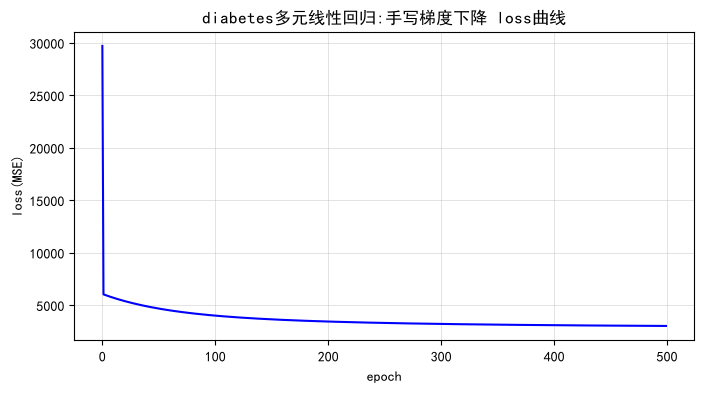

In [32]:
plt.figure(figsize=(8,4))
plt.plot(losses2,'b-')
plt.xlabel('epoch')
plt.ylabel('loss(MSE)')
plt.title('diabetes多元线性回归:手写梯度下降 loss曲线')
plt.grid(True)
plt.show()

In [33]:
#与sklearn做对比
#sklearn基准

sk = LinearRegression()
sk.fit(X_train,y_train)
sk_pred = sk.predict(X_test)
sk_mse = mean_squared_error(y_test,sk_pred)

print(f'手写梯度下降 测试MSE = {test_mse:.3f}')
print(f'sklearn 最小二乘 测试MSE = {sk_mse:.3f}')
print(f'偏置差异：{abs(b-sk.intercept_):.3f}')
print()

手写梯度下降 测试MSE = 2882.070
sklearn 最小二乘 测试MSE = 2900.194
偏置差异：0.292



lr = 1.2 时 loss 序列前10：[29711.32 14519.41  9010.85  6989.53  6224.67  5913.09  5765.61  5678.09
  5613.01  5556.84]
lr = 1.2 时最终loss：3606.94


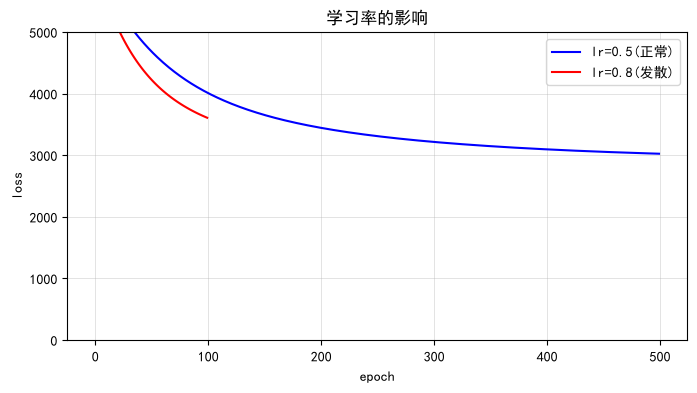

In [34]:
_,_,losses_big = gradient_descent_multi(X_train,y_train,lr=0.8,epochs=100)
print(f'lr = 1.2 时 loss 序列前10：{losses_big[:10].round(2)}')
print(f'lr = 1.2 时最终loss：{losses_big[-1]:.2f}')

plt.figure(figsize=(8,4))
plt.plot(losses2,'b-',label='lr=0.5(正常)')
plt.plot(losses_big,'r-',label='lr=0.8(发散)')
plt.ylim(0,min(5000,max(losses2[-1]*3,1)))
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('学习率的影响')
plt.legend()
plt.grid(True)
plt.show()

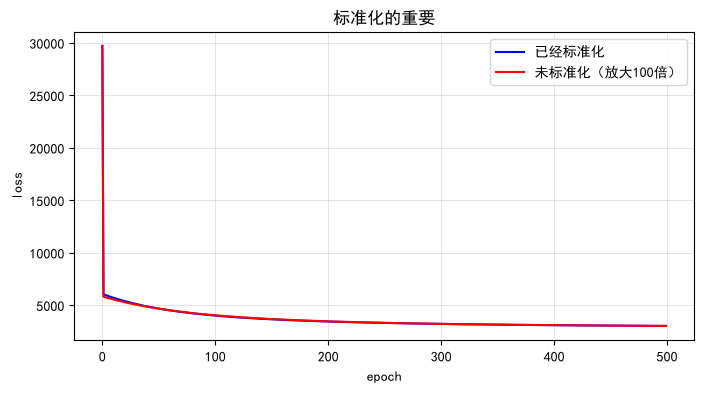

In [35]:
# 如果不标准化

X_bad = X_train.copy()
X_bad[:,0] *= 20
_,_,losses_bad = gradient_descent_multi(X_bad,y_train,lr=0.5,epochs=500)

plt.figure(figsize=(8,4))
plt.plot(losses2,'b-',label='已经标准化')
plt.plot(losses_bad,'r-',label='未标准化（放大100倍）')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('标准化的重要')
plt.legend()
plt.grid(True)
plt.show()

# 作业部分

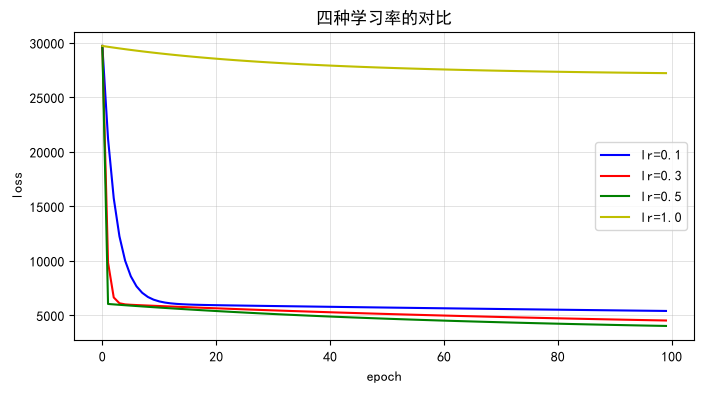

In [36]:
#作业1：把学习率变成0.1、0.3、0.5、1.0，画四条loss曲线去对比
_,_,losses_z0 = gradient_descent_multi(X_train,y_train,lr=0.1,epochs=100)
_,_,losses_z1 = gradient_descent_multi(X_train,y_train,lr=0.3,epochs=100)
_,_,losses_z2 = gradient_descent_multi(X_train,y_train,lr=0.5,epochs=100)
_,_,losses_z3 = gradient_descent_multi(X_train,y_train,lr=1.0,epochs=100)

plt.figure(figsize=(8,4))
plt.plot(losses_z0,'b-',label='lr=0.1')
plt.plot(losses_z1,'r-',label='lr=0.3')
plt.plot(losses_z2,'g-',label='lr=0.5')
plt.plot(losses_z3,'y-',label='lr=1.0')

plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('四种学习率的对比')
plt.legend()
plt.grid(True)
plt.show()

In [37]:
#作业2：尝试用sklearn的Clalifornia Housing数据集，注意下先做标准化
import numpy as  np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import  mean_squared_error

np.set_printoptions(precision=3, suppress=True)

plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus'] = False
np.random.seed(42)
print('Success!!!')


Success!!!


In [38]:
#加载数据集做初步评估
housing = fetch_california_housing()
X, y = housing.data, housing.target

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 标准化
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X 形状：", X.shape)
print("y 形状：", y.shape)
print("特征名：", housing.feature_names)
print('X 的均值：',X.mean(axis=0).round(3))
print('X 的标准差',X.std(axis=0).round(3))
print("y 范围：", y.min().round(2), "~", y.max().round(2))
print('样本数一致：',X.shape[0] == y.shape[0])

print('训练集：',X_train.shape,y_train.shape)
print('测试集：',X_test.shape,y_test.shape)

print("训练集标准化后均值：", X_train_scaled.mean(axis=0).round(3))
print("训练集标准化后标准差：", X_train_scaled.std(axis=0).round(3))

X 形状： (20640, 8)
y 形状： (20640,)
特征名： ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X 的均值： [   3.871   28.639    5.429    1.097 1425.477    3.071   35.632 -119.57 ]
X 的标准差 [   1.9     12.585    2.474    0.474 1132.435   10.386    2.136    2.003]
y 范围： 0.15 ~ 5.0
样本数一致： True
训练集： (16512, 8) (16512,)
测试集： (4128, 8) (4128,)
训练集标准化后均值： [-0. -0.  0. -0. -0. -0.  0. -0.]
训练集标准化后标准差： [1. 1. 1. 1. 1. 1. 1. 1.]


In [39]:
# 多元线性回归梯度下降函数
def gradient_descent_multi(X_train_scaled, y_train, lr=0.05, epochs=10000):
    n, d = X_train_scaled.shape
    w = np.zeros(d)
    b = 0.0
    losses = []

    for epoch in range(epochs):
        # TODO 1: 前向计算
        pred = X_train_scaled @ w + b
        err = pred - y_train

        # TODO 2: 计算梯度
        dw = (2 / n) * (X_train_scaled.T @ err)
        db = (2 / n) * np.sum(err)

        # TODO 3: 更新参数
        w -= lr * dw
        b -= lr * db

        # TODO 4: 记录 loss
        loss = np.mean(err ** 2)
        losses.append(loss)

    return w, b, np.array(losses)

In [40]:
# 训练
w, b, losses_h = gradient_descent_multi(
    X_train_scaled,
    y_train,
    lr=0.05,
    epochs=10000
)

print("最终 loss：", losses_h[-1].round(4))
print("学到的 w：", np.round(w, 4))
print("学到的 b：", round(b, 4))

# 测试集预测与评估
y_pred = X_test_scaled @ w + b
test_mse = mean_squared_error(y_test, y_pred)
print(f'测试 MSE：{test_mse:.3f}')

最终 loss： 0.5179
学到的 w： [ 0.854  0.122 -0.294  0.339 -0.002 -0.041 -0.897 -0.87 ]
学到的 b： 2.0719
测试 MSE：0.556


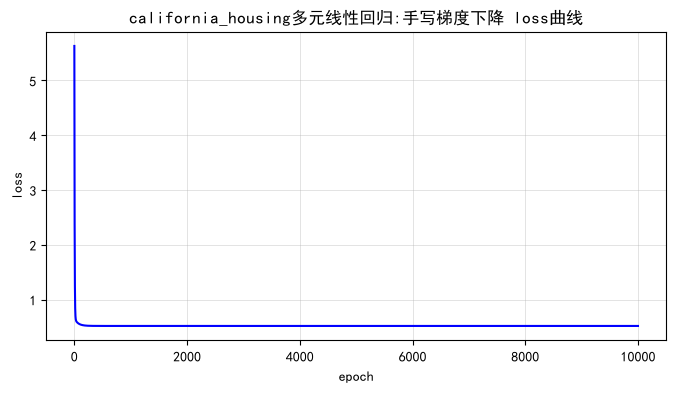

In [41]:
plt.figure(figsize=(8,4))
plt.plot(losses_h,'b-')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('california_housing多元线性回归:手写梯度下降 loss曲线')
plt.grid(True)

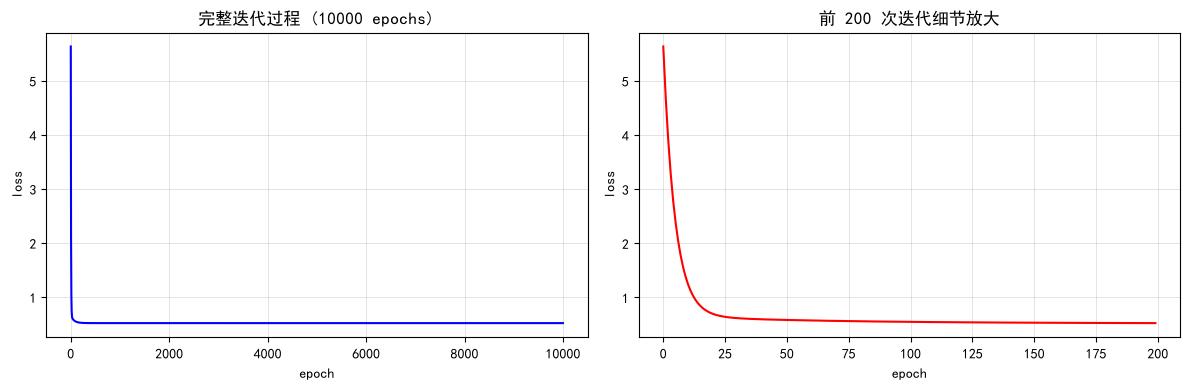

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 左图：完整 10000 次迭代
axes[0].plot(losses_h, 'b-')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].set_title('完整迭代过程 (10000 epochs)')
axes[0].grid(True)

# 右图：前 200 次迭代细节
axes[1].plot(losses_h[:200], 'r-')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
axes[1].set_title('前 200 次迭代细节放大')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [43]:
# 和 sklearn LinearRegression 对比
sk = LinearRegression()
sk.fit(X_train_scaled, y_train)
sk_pred = sk.predict(X_test_scaled)
sk_mse = mean_squared_error(y_test, sk_pred)

print(f'手写梯度下降测试MSE = {test_mse:.3f}')
print(f'sklearn 最小二乘测试MSE = {sk_mse:.3f}')
print(f'偏置差异：{abs(b-sk.intercept_):.20f}')
print()

手写梯度下降测试MSE = 0.556
sklearn 最小二乘测试MSE = 0.556
偏置差异：0.00000000000000177636



In [44]:
#作业3：为什么DL不用解析解而用梯度下降？
# 1. 计算复杂度高，DL往往面对百万亿万次参数，使用解析解一步步求逆在计算和内存不可能行得通。
# 2. 解析解适合线性场景，而DL里神经网络并不是线性，是多结构的复合函数。